# 02 — Treinamento: Baseline e ResNet-50

Treina um baseline CNN do zero e a ResNet-50 (transfer learning em 2 fases) com `class_weight="balanced"`, salva os modelos em `models/` e grava as predições de validação e teste em `results/predictions/`.

In [1]:
import os, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("triagem-raio-x").exists():
        os.system("git clone https://github.com/LuizCenci/triagem-raio-x")
    os.chdir("triagem-raio-x")
    os.system("pip install -q kagglehub seaborn scikit-learn pandas")
else:
    os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())

In [2]:
import json
import shutil
from datetime import datetime

import keras
import matplotlib
matplotlib.use("Agg") if "ipykernel" not in sys.modules else None
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

from src.config import RESULTS_DIR, ROOT, SEED, SPLITS_DIR
from src.download import download_dataset
from src.metadata import attach_paths
from src.pipeline import AUGMENT, IMG_SIZE, make_dataset
from src.split import load_splits

keras.utils.set_random_seed(SEED)

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_DIR = RESULTS_DIR / "training"
TRAIN_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = RESULTS_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVE_MODELS = None
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_MODELS = Path("/content/drive/MyDrive/triagem-raio-x/models")
    DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
    for f in DRIVE_MODELS.glob("*.keras"):
        if not (MODELS_DIR / f.name).exists():
            shutil.copy2(f, MODELS_DIR / f.name)


def sync_to_drive(path: Path) -> None:
    if DRIVE_MODELS is not None and path.exists():
        shutil.copy2(path, DRIVE_MODELS / path.name)


root = download_dataset()
splits = {name: attach_paths(df, root) for name, df in load_splits(SPLITS_DIR).items()}
for name, df in splits.items():
    print(f"{name}: {len(df)} imagens ({df.patient_id.nunique()} pacientes, {100*df.label.mean():.1f}% ALTERADA)")

train: 3931 imagens (2961 pacientes, 45.9% ALTERADA)
validation: 531 imagens (423 pacientes, 42.7% ALTERADA)
test: 1144 imagens (846 pacientes, 46.3% ALTERADA)


In [3]:
y_train = splits["train"]["label"].to_numpy()
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print("class_weight:", class_weight)

class_weight: {0: 0.9245061147695203, 1: 1.0889196675900277}


In [4]:
def make_metrics():
    return [
        keras.metrics.AUC(name="auc"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.Precision(name="precision"),
    ]


def build_baseline() -> keras.Model:
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = keras.layers.Rescaling(1.0 / 255.0)(inputs)
    for i in range(3):
        x = keras.layers.Conv2D(32 * (2 ** i), 3, activation="relu")(x)
        x = keras.layers.MaxPooling2D()(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="baseline")


identity = lambda x: x
train_ds_base = make_dataset(splits["train"], identity, batch_size=32, shuffle=True, augment=AUGMENT)
val_ds_base = make_dataset(splits["validation"], identity, batch_size=32, shuffle=False)

baseline_path = MODELS_DIR / "baseline.keras"
baseline_ckpt = MODELS_DIR / "baseline_ckpt.keras"
hist_base_path = TRAIN_DIR / "history_baseline.csv"

if baseline_path.exists() and hist_base_path.exists():
    print("Retomando baseline salvo:", baseline_path)
    baseline = keras.models.load_model(baseline_path)
    hist_baseline_df = pd.read_csv(hist_base_path)
else:
    if baseline_ckpt.exists():
        print("Retomando checkpoint do baseline:", baseline_ckpt)
        baseline = keras.models.load_model(baseline_ckpt)
    else:
        baseline = build_baseline()
    baseline.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=make_metrics(),
    )
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(baseline_ckpt), monitor="val_auc", mode="max", save_best_only=True),
    ]
    hist = baseline.fit(
        train_ds_base,
        validation_data=val_ds_base,
        epochs=15,
        class_weight=class_weight,
        callbacks=callbacks,
    )
    baseline = keras.models.load_model(baseline_ckpt)
    baseline.save(baseline_path)
    sync_to_drive(baseline_ckpt)
    sync_to_drive(baseline_path)
    hist_baseline_df = pd.DataFrame(hist.history)
    hist_baseline_df.to_csv(hist_base_path, index=False)

print(f"Baseline melhor val_auc: {hist_baseline_df['val_auc'].max():.4f}")

Epoch 1/15


C:\triagem-raio-x\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/123 ━━━━━━━━━━━━━━━━━━━━ 2:19 1s/step - auc: 0.4502 - loss: 0.6851 - precision: 0.3438 - recall: 1.0000

  2/123 ━━━━━━━━━━━━━━━━━━━━ 30s 254ms/step - auc: 0.5184 - loss: 0.6783 - precision: 0.3438 - recall: 0.5000

  3/123 ━━━━━━━━━━━━━━━━━━━━ 28s 241ms/step - auc: 0.5063 - loss: 0.6733 - precision: 0.3438 - recall: 0.3333

  4/123 ━━━━━━━━━━━━━━━━━━━━ 25s 213ms/step - auc: 0.4782 - loss: 0.6780 - precision: 0.3438 - recall: 0.2340

... (992 outputs left out)

122/123 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - auc: 0.5374 - loss: 0.6915 - precision: 0.4944 - recall: 0.5416

123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - auc: 0.5373 - loss: 0.6915 - precision: 0.4950 - recall: 0.5440

123/123 ━━━━━━━━━━━━━━━━━━━━ 25s 199ms/step - auc: 0.5373 - loss: 0.6915 - precision: 0.4950 - recall: 0.5440 - val_auc: 0.5570 - val_loss: 0.6977 - val_precision: 0.4495 - val_recall: 0.7841


Baseline melhor val_auc: 0.5666


In [5]:
preprocess_resnet = keras.applications.resnet50.preprocess_input
train_ds_res = make_dataset(splits["train"], preprocess_resnet, batch_size=32, shuffle=True, augment=AUGMENT)
val_ds_res = make_dataset(splits["validation"], preprocess_resnet, batch_size=32, shuffle=False)


def build_resnet50() -> keras.Model:
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    base = keras.applications.ResNet50(include_top=False, weights="imagenet", name="resnet50")
    base.trainable = False
    x = base(inputs, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(0.3, name="dropout")(x)
    outputs = keras.layers.Dense(1, activation="sigmoid", name="head")(x)
    return keras.Model(inputs, outputs, name="resnet50_triagem")


fase1_path = MODELS_DIR / "resnet50_fase1.keras"
fase1_ckpt = MODELS_DIR / "resnet50_fase1_ckpt.keras"
hist_f1_path = TRAIN_DIR / "history_resnet50_fase1.csv"

if fase1_path.exists() and hist_f1_path.exists():
    print("Retomando ResNet-50 fase 1 salva:", fase1_path)
    resnet = keras.models.load_model(fase1_path)
    hist_f1_df = pd.read_csv(hist_f1_path)
else:
    if fase1_ckpt.exists():
        print("Retomando checkpoint da ResNet-50 fase 1:", fase1_ckpt)
        resnet = keras.models.load_model(fase1_ckpt)
    else:
        resnet = build_resnet50()
    resnet.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=make_metrics(),
    )
    callbacks_f1 = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(fase1_ckpt), monitor="val_auc", mode="max", save_best_only=True),
    ]
    hist_f1 = resnet.fit(
        train_ds_res,
        validation_data=val_ds_res,
        epochs=10,
        class_weight=class_weight,
        callbacks=callbacks_f1,
    )
    resnet = keras.models.load_model(fase1_ckpt)
    resnet.save(fase1_path)
    sync_to_drive(fase1_ckpt)
    sync_to_drive(fase1_path)
    hist_f1_df = pd.DataFrame(hist_f1.history)
    hist_f1_df.to_csv(hist_f1_path, index=False)

print(f"ResNet-50 fase 1 melhor val_auc: {hist_f1_df['val_auc'].max():.4f}")

       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 1:57 1us/step

   81920/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:58 3us/step

  131072/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:08 2us/step

  147456/94765736 ━━━━━━━━━━━━━━━━━━━━ 3:51 2us/step

  253952/94765736 ━━━━━━━━━━━━━━━━━━━━ 2:33 2us/step

... (954 outputs left out)

122/123 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - auc: 0.6977 - loss: 0.6445 - precision: 0.6089 - recall: 0.6415

123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - auc: 0.6985 - loss: 0.6437 - precision: 0.6104 - recall: 0.6432

123/123 ━━━━━━━━━━━━━━━━━━━━ 76s 447ms/step - auc: 0.6985 - loss: 0.6437 - precision: 0.6104 - recall: 0.6432 - val_auc: 0.7120 - val_loss: 0.6368 - val_precision: 0.5725 - val_recall: 0.6784


ResNet-50 fase 1 melhor val_auc: 0.7205


In [6]:
resnet_path = MODELS_DIR / "resnet50.keras"
fase2_ckpt = MODELS_DIR / "resnet50_fase2_ckpt.keras"
hist_f2_path = TRAIN_DIR / "history_resnet50_fase2.csv"

if resnet_path.exists() and hist_f2_path.exists():
    print("Retomando ResNet-50 fase 2 salva:", resnet_path)
    resnet = keras.models.load_model(resnet_path)
    hist_f2_df = pd.read_csv(hist_f2_path)
else:
    if fase2_ckpt.exists():
        print("Retomando checkpoint da ResNet-50 fase 2:", fase2_ckpt)
        resnet = keras.models.load_model(fase2_ckpt)
    base = resnet.get_layer("resnet50")
    base.trainable = True
    unfreeze = False
    for layer in base.layers:
        if layer.name == "conv5_block1_1_conv":
            unfreeze = True
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = unfreeze

    trainable_names = [l.name for l in base.layers if l.trainable]
    print(f"Camadas descongeladas na base: {len(trainable_names)} (primeira: {trainable_names[0]})")

    resnet.compile(
        optimizer=keras.optimizers.Adam(1e-5),
        loss="binary_crossentropy",
        metrics=make_metrics(),
    )
    callbacks_f2 = [
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(fase2_ckpt), monitor="val_auc", mode="max", save_best_only=True),
    ]
    hist_f2 = resnet.fit(
        train_ds_res,
        validation_data=val_ds_res,
        epochs=10,
        class_weight=class_weight,
        callbacks=callbacks_f2,
    )
    resnet = keras.models.load_model(fase2_ckpt)
    resnet.save(resnet_path)
    sync_to_drive(fase2_ckpt)
    sync_to_drive(resnet_path)
    hist_f2_df = pd.DataFrame(hist_f2.history)
    hist_f2_df.to_csv(hist_f2_path, index=False)

print(f"ResNet-50 fase 2 melhor val_auc: {hist_f2_df['val_auc'].max():.4f}")

Camadas descongeladas na base: 22 (primeira: conv5_block1_1_conv)
Epoch 1/10


C:\triagem-raio-x\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/123 ━━━━━━━━━━━━━━━━━━━━ 8:10 4s/step - auc: 0.5375 - loss: 0.7537 - precision: 0.4167 - recall: 0.4167

  2/123 ━━━━━━━━━━━━━━━━━━━━ 1:01 511ms/step - auc: 0.6716 - loss: 0.6527 - precision: 0.5556 - recall: 0.5769

  3/123 ━━━━━━━━━━━━━━━━━━━━ 1:01 509ms/step - auc: 0.6763 - loss: 0.6734 - precision: 0.6000 - recall: 0.6000

  4/123 ━━━━━━━━━━━━━━━━━━━━ 1:00 507ms/step - auc: 0.7112 - loss: 0.6333 - precision: 0.6140 - recall: 0.6250

... (867 outputs left out)

122/123 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step - auc: 0.8157 - loss: 0.5234 - precision: 0.6940 - recall: 0.7391

123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 472ms/step - auc: 0.8161 - loss: 0.5231 - precision: 0.6953 - recall: 0.7396

123/123 ━━━━━━━━━━━━━━━━━━━━ 65s 522ms/step - auc: 0.8161 - loss: 0.5231 - precision: 0.6953 - recall: 0.7396 - val_auc: 0.7220 - val_loss: 0.6413 - val_precision: 0.6058 - val_recall: 0.5551


ResNet-50 fase 2 melhor val_auc: 0.7388


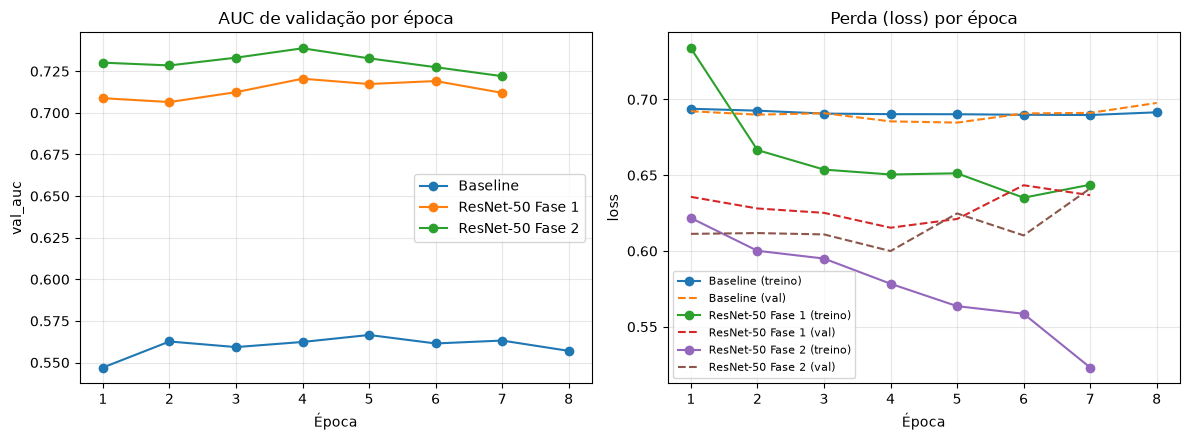

In [7]:
histories = {
    "Baseline": hist_baseline_df,
    "ResNet-50 Fase 1": hist_f1_df,
    "ResNet-50 Fase 2": hist_f2_df,
}
hist_baseline_df.to_csv(TRAIN_DIR / "history_baseline.csv", index=False)
hist_f1_df.to_csv(TRAIN_DIR / "history_resnet50_fase1.csv", index=False)
hist_f2_df.to_csv(TRAIN_DIR / "history_resnet50_fase2.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, hdf in histories.items():
    epochs = range(1, len(hdf) + 1)
    axes[0].plot(epochs, hdf["val_auc"], marker="o", label=label)
    axes[1].plot(epochs, hdf["loss"], marker="o", label=f"{label} (treino)")
    axes[1].plot(epochs, hdf["val_loss"], linestyle="--", label=f"{label} (val)")

axes[0].set_title("AUC de validação por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("val_auc")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Perda (loss) por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("loss")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "curvas_treino.png", dpi=150)
plt.show()

In [8]:
PRED_COLS = ["image", "patient_id", "label", "sex", "age_group", "view", "p_alterada"]

models_cfg = {
    "baseline": (baseline, identity),
    "resnet50": (resnet, preprocess_resnet),
}

val_preds = {}
for model_name, (mdl, preproc) in models_cfg.items():
    for split_name in ("validation", "test"):
        df_split = splits[split_name]
        ds = make_dataset(df_split, preproc, batch_size=32, shuffle=False)
        probs = mdl.predict(ds, verbose=0).reshape(-1)
        out = df_split[["image", "patient_id", "label", "sex", "age_group", "view"]].copy()
        out["p_alterada"] = probs
        out = out[PRED_COLS]
        assert len(out) == len(df_split), f"Contagem divergente em {model_name}_{split_name}"
        out_path = PRED_DIR / f"{model_name}_{split_name}.csv"
        out.to_csv(out_path, index=False)
        print(f"Salvo {out_path.name}: {len(out)} linhas | p in [{out.p_alterada.min():.4f}, {out.p_alterada.max():.4f}]")
        if split_name == "validation":
            val_preds[model_name] = out

Salvo baseline_validation.csv: 531 linhas | p in [0.4391, 0.7434]


Salvo baseline_test.csv: 1144 linhas | p in [0.4377, 0.6847]


Salvo resnet50_validation.csv: 531 linhas | p in [0.0505, 0.9759]


Salvo resnet50_test.csv: 1144 linhas | p in [0.0445, 0.9574]


In [9]:
exp_path = RESULTS_DIR / "experiments.csv"
today = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

configs = {
    "baseline": {
        "arquitetura": "3x(Conv2D+MaxPool)+GAP+Dense",
        "img_size": IMG_SIZE,
        "batch_size": 32,
        "optimizer": "Adam(1e-3)",
        "epochs_max": 15,
        "patience": 3,
        "class_weight": "balanced",
        "augment": ["RandomRotation(0.03)", "RandomZoom(0.1)", "RandomContrast(0.1)"],
    },
    "resnet50": {
        "arquitetura": "ResNet50(ImageNet)+GAP+Dropout(0.3)+Dense",
        "img_size": IMG_SIZE,
        "batch_size": 32,
        "fase1": {"optimizer": "Adam(1e-3)", "epochs_max": 10, "base_trainable": False},
        "fase2": {"optimizer": "Adam(1e-5)", "epochs_max": 10, "unfreeze_from": "conv5_block1_1_conv", "bn_frozen": True},
        "patience": 3,
        "class_weight": "balanced",
        "augment": ["RandomRotation(0.03)", "RandomZoom(0.1)", "RandomContrast(0.1)"],
    },
}

rows = []
for model_name in ("baseline", "resnet50"):
    vp = val_preds[model_name]
    y_val = vp["label"].to_numpy()
    p_val = vp["p_alterada"].to_numpy()
    rows.append({
        "data": today,
        "modelo": model_name,
        "config": json.dumps(configs[model_name], ensure_ascii=False),
        "seed": SEED,
        "val_auc": round(float(roc_auc_score(y_val, p_val)), 6),
        "val_recall@0.5": round(float(recall_score(y_val, p_val >= 0.5)), 6),
    })

new_exp = pd.DataFrame(rows)
if exp_path.exists():
    prev = pd.read_csv(exp_path)
    pd.concat([prev, new_exp], ignore_index=True).to_csv(exp_path, index=False)
else:
    new_exp.to_csv(exp_path, index=False)

pd.read_csv(exp_path)

,data,modelo,config,seed,val_auc,val_recall@0.5
0,2026-11-25 09:34:39,baseline,"{""arquitetura"": ""3x(Conv2D+MaxPool)+GAP+Dense""...",42,0.565529,0.224670
1,2026-11-25 09:34:39,resnet50,"{""arquitetura"": ""ResNet50(ImageNet)+GAP+Dropou...",42,0.738653,0.546256


In [10]:
for f in ["baseline_validation", "baseline_test", "resnet50_validation", "resnet50_test"]:
    d = pd.read_csv(PRED_DIR / f"{f}.csv")
    print(f, len(d), d["p_alterada"].between(0, 1).all())

baseline_validation 531 True
baseline_test 1144 True
resnet50_validation 531 True
resnet50_test 1144 True
